# Demons Field Estimation — Single-Frame Debug

Step-by-step visualization of a single Demons registration (reference frame vs.
one frame away from it), to see *why* the field is drifting instead of just
seeing the end result. Mirrors the loading cells in `MC_3D_test.ipynb` but
skips straight to a single frame pair and unrolls the registration loop so
every intermediate can be inspected.

In [1]:
%reload_ext autoreload
%autoreload 2

import os
from pathlib import Path

print(Path().cwd())
os.chdir(Path(os.getcwd()).parent)
print(Path().cwd())

/home/yuanshanwu/Documents/GitHub/QuantUS/engines/ceus/CLI-Demos
/home/yuanshanwu/Documents/GitHub/QuantUS/engines/ceus


## Load Data

Same scan/segmentation loading as `MC_3D_test.ipynb` — point these at the same case.

In [2]:
scan_type = 'nifti'

CEUS_scan_path = '/home/yuanshanwu/Documents/TUL/CEUS-Studies/P07-V02-CE01/UCSD-P07-V02-CE01RUN2_09.39.44_mf_sip_capture_50_2_1_0_CEUS.nii'
bmode_scan_path = '/home/yuanshanwu/Documents/TUL/CEUS-Studies/P07-V02-CE01/UCSD-P07-V02-CE01RUN2_09.39.44_mf_sip_capture_50_2_1_0_BMODE.nii'
scan_loader_kwargs = {}

from src.entrypoints import scan_loading_step

image_data = scan_loading_step(scan_type, CEUS_scan_path, **scan_loader_kwargs)
bmode_image_data = scan_loading_step(scan_type, bmode_scan_path, **scan_loader_kwargs)
print(f"B-mode shape: {bmode_image_data.pixel_data.shape}")

B-mode shape: (195, 144, 145, 530)


In [4]:
seg_type = 'nifti'

seg_path = '/home/yuanshanwu/Documents/TUL/CEUS-Studies/P07-V02-CE01/no_MC_VOI_#50.nii.gz'
seg_loader_kwargs = {}

from src.entrypoints import seg_loading_step

seg_data = seg_loading_step(seg_type, image_data, seg_path, CEUS_scan_path, **seg_loader_kwargs)
print(f"VOI mask shape: {seg_data.seg_mask.shape}, voxels: {(seg_data.seg_mask > 0).sum()}")

VOI mask shape: (195, 144, 145), voxels: 25241


## Pick the reference frame and one target frame

Only a single frame pair is registered below — the VOI's reference frame
against one frame `frame_offset` away from it — so every step of that one
registration can be inspected instead of scrolling through a whole sequence.

In [5]:
reference_frame = 50       # the frame the VOI was drawn on
frame_offset = 1           # +1 = one frame after reference, -1 = one frame before
target_frame = reference_frame + frame_offset

crop_padding = 25          # must be >= the true excursion between the two frames

print(f"Reference frame: {reference_frame}")
print(f"Target frame:    {target_frame}  (offset {frame_offset:+d})")

Reference frame: 50
Target frame:    51  (offset +1)


## Extract the registration crop (raw, undenoised)

In [6]:
import numpy as np
from src.seg_preprocessing.motion_compensation_3d import BoundingBox3D
from src.seg_preprocessing.demon_motion_compensation_3d import (
    _denoise_nlm, _demons_velocity, warp_by_field, register_demons_3d,
)
from scipy.ndimage import gaussian_filter

voi_mask = seg_data.seg_mask
volume_shape = bmode_image_data.pixel_data.shape[:-1]

crop = BoundingBox3D.from_mask(voi_mask, padding=crop_padding).clip(volume_shape)
fixed_raw = crop.extract_from_volume(bmode_image_data.pixel_data[..., reference_frame]).astype(np.float32)
moving_raw = crop.extract_from_volume(bmode_image_data.pixel_data[..., target_frame]).astype(np.float32)
voi_crop = crop.extract_from_volume(voi_mask)

print(f"Crop shape: {fixed_raw.shape}")
print(f"Crop bbox: X=[{crop.x_min},{crop.x_max}) Y=[{crop.y_min},{crop.y_max}) Z=[{crop.z_min},{crop.z_max})")

Crop shape: (96, 84, 89)
Crop bbox: X=[51,147) Y=[38,122) Z=[23,112)


## Shared plotting helpers (same conventions as `MC_3D_test.ipynb`)

In [7]:
%matplotlib inline
import matplotlib.pyplot as plt
from scipy.ndimage import binary_erosion

def enhance_bmode_noise(image_slice, p_low_percentile=30.0, p_high_percentile=98.0):
    non_zero = image_slice[image_slice != 0]
    if non_zero.size == 0:
        return np.zeros_like(image_slice, dtype=np.uint8)
    p_low = np.percentile(non_zero, p_low_percentile)
    p_high = np.percentile(non_zero, p_high_percentile)
    clipped_slice = np.clip(image_slice, p_low, p_high)
    denom = (p_high - p_low) if p_high > p_low else 1.0
    return ((clipped_slice - p_low) / denom * 255).astype(np.uint8)

def get_mask_boundary(mask_slice):
    if mask_slice.max() == 0:
        return np.zeros_like(mask_slice, dtype=bool)
    eroded = binary_erosion(mask_slice)
    return mask_slice.astype(bool) & ~eroded

def get_voi_center(mask_3d):
    coords = np.where(mask_3d > 0)
    if len(coords[0]) == 0:
        return None, None, None
    return int(np.mean(coords[0])), int(np.mean(coords[1])), int(np.mean(coords[2]))

lateral_c, depth_c, elevation_c = get_voi_center(voi_crop)
print(f"VOI center (crop-local): X={lateral_c} Y={depth_c} Z={elevation_c}")

VOI center (crop-local): X=47 Y=41 Z=43


## Step 1 — raw fixed vs. moving vs. difference

What Demons has to work with before any denoising. If the tumor isn't even
visibly in roughly the same place in the difference image, no amount of
registration tuning will fix it — check `crop_padding` first.

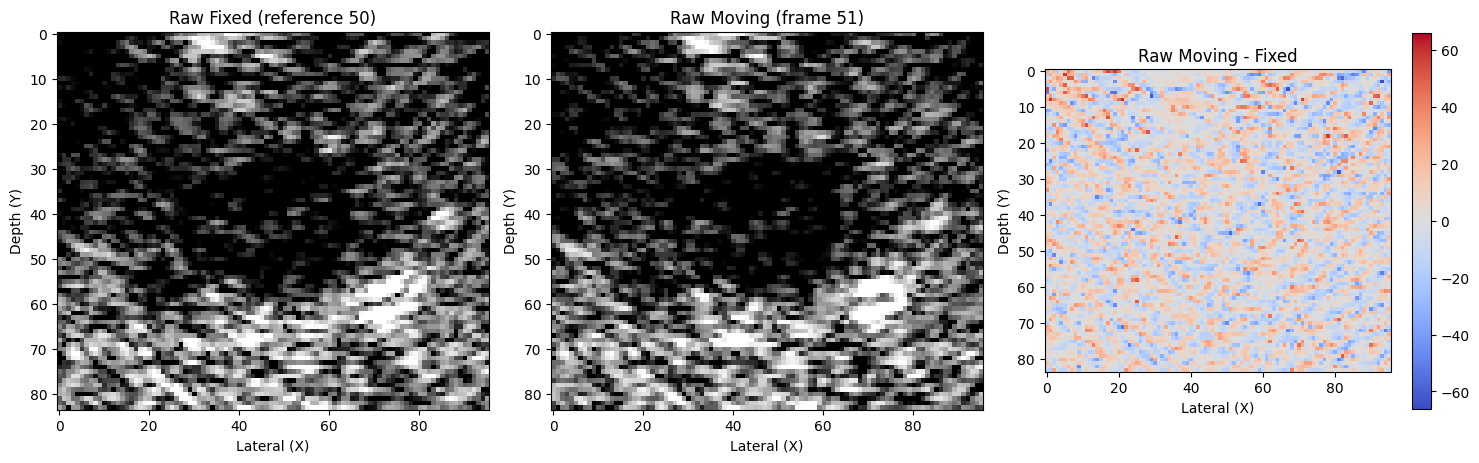

In [8]:
def show_pair(fixed_img, moving_img, title_prefix=''):
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(np.transpose(enhance_bmode_noise(fixed_img[:, :, elevation_c])), cmap='gray')
    axes[0].set_title(f'{title_prefix}Fixed (reference {reference_frame})')
    axes[1].imshow(np.transpose(enhance_bmode_noise(moving_img[:, :, elevation_c])), cmap='gray')
    axes[1].set_title(f'{title_prefix}Moving (frame {target_frame})')
    diff = np.transpose(moving_img[:, :, elevation_c] - fixed_img[:, :, elevation_c])
    im = axes[2].imshow(diff, cmap='coolwarm', vmin=-np.abs(diff).max(), vmax=np.abs(diff).max())
    axes[2].set_title(f'{title_prefix}Moving - Fixed')
    fig.colorbar(im, ax=axes[2], shrink=0.8)
    for ax in axes:
        ax.set_xlabel('Lateral (X)'); ax.set_ylabel('Depth (Y)')
    plt.tight_layout()
    plt.show()

show_pair(fixed_raw, moving_raw, title_prefix='Raw ')

## Step 2 — non-local means denoising

Compare raw vs. denoised for both frames, and the gradient magnitude of the
fixed image before/after — gradient is exactly what the Demons force uses,
so a cleaner gradient map here should mean a more stable field below.

In [ ]:
nlm_patch_size = 5
nlm_patch_distance = 6
nlm_h_factor = 0.8
nlm_fast_mode = True

fixed_denoised = _denoise_nlm(fixed_raw, nlm_patch_size, nlm_patch_distance, nlm_h_factor, nlm_fast_mode)
moving_denoised = _denoise_nlm(moving_raw, nlm_patch_size, nlm_patch_distance, nlm_h_factor, nlm_fast_mode)

show_pair(fixed_denoised, moving_denoised, title_prefix='Denoised ')

In [ ]:
def grad_magnitude(vol):
    gx, gy, gz = np.gradient(vol)
    return np.sqrt(gx**2 + gy**2 + gz**2)

grad_raw = grad_magnitude(fixed_raw)[:, :, elevation_c]
grad_denoised = grad_magnitude(fixed_denoised)[:, :, elevation_c]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
v = max(grad_raw.max(), grad_denoised.max())
axes[0].imshow(np.transpose(grad_raw), cmap='inferno', vmin=0, vmax=v)
axes[0].set_title('|gradient(fixed)| — raw')
axes[1].imshow(np.transpose(grad_denoised), cmap='inferno', vmin=0, vmax=v)
axes[1].set_title('|gradient(fixed)| — denoised')
for ax in axes:
    ax.set_xlabel('Lateral (X)'); ax.set_ylabel('Depth (Y)')
plt.tight_layout()
plt.show()

print(f"Mean |gradient|: raw={grad_raw.mean():.2f}  denoised={grad_denoised.mean():.2f}")

## Step 3 — run Demons with checkpoints

Same math as `register_demons_3d`, unrolled so the field / warped image / MSE
can be captured every `checkpoint_every` iterations instead of only seeing
the final result.

In [ ]:
use_denoise = True   # toggle to compare against the raw (undenoised) pair

fixed_in = fixed_denoised if use_denoise else fixed_raw
moving_in = moving_denoised if use_denoise else moving_raw

n_iterations = 150
sigma_fluid = 1.0
sigma_diffusion = 2.0
alpha = 1.0
checkpoint_every = 10

def run_demons_with_checkpoints(fixed, moving, n_iterations, sigma_fluid, sigma_diffusion, alpha, checkpoint_every):
    fixed = np.ascontiguousarray(fixed, dtype=np.float32)
    moving = np.ascontiguousarray(moving, dtype=np.float32)
    field = np.zeros(fixed.shape + (3,), dtype=np.float32)
    grad_fixed = np.gradient(fixed)

    checkpoints = []  # list of dicts: iter, field, warped, mse
    for it in range(n_iterations):
        warped = warp_by_field(moving, field, order=1)
        grad_moving = np.gradient(warped)

        v = _demons_velocity(fixed, warped, grad_fixed, grad_moving, alpha)
        for i in range(3):
            v[..., i] = gaussian_filter(v[..., i], sigma_fluid)

        field = field + v
        for i in range(3):
            field[..., i] = gaussian_filter(field[..., i], sigma_diffusion)

        warped_now = warp_by_field(moving, field, order=1)
        mse = float(np.mean((fixed - warped_now) ** 2))

        if it % checkpoint_every == 0 or it == n_iterations - 1:
            checkpoints.append({'iter': it, 'field': field.copy(), 'warped': warped_now, 'mse': mse})

    return checkpoints

checkpoints = run_demons_with_checkpoints(
    fixed_in, moving_in, n_iterations, sigma_fluid, sigma_diffusion, alpha, checkpoint_every
)
print(f"Captured {len(checkpoints)} checkpoints across {n_iterations} iterations")

## Step 4 — MSE convergence curve

Smoothly decreasing = converging normally. Flat/oscillating/increasing means
the field is not settling — usually `sigma_fluid`/`sigma_diffusion` too small
relative to the noise remaining, or `alpha` too low.

In [ ]:
iters = [c['iter'] for c in checkpoints]
mses = [c['mse'] for c in checkpoints]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(iters, mses, marker='o')
ax.set_xlabel('Iteration')
ax.set_ylabel('MSE (fixed vs warped moving)')
ax.set_title('Demons convergence')
plt.tight_layout()
plt.show()

## Step 5 — first / middle / last checkpoint: warped image, |diff|, |field|

Watch the warped moving image visually approach the fixed image (top row of
each triple), and the field magnitude heatmap to see where — and how much —
the algorithm thinks things moved.

In [ ]:
picks = [checkpoints[0], checkpoints[len(checkpoints) // 2], checkpoints[-1]]

fig, axes = plt.subplots(len(picks), 3, figsize=(15, 5 * len(picks)))
field_mag_max = max(np.linalg.norm(c['field'], axis=-1)[:, :, elevation_c].max() for c in picks)

for row, c in enumerate(picks):
    warped_slice = np.transpose(c['warped'][:, :, elevation_c])
    fixed_slice = np.transpose(fixed_in[:, :, elevation_c])
    diff_slice = np.abs(warped_slice - fixed_slice)
    field_mag_slice = np.transpose(np.linalg.norm(c['field'], axis=-1)[:, :, elevation_c])

    axes[row, 0].imshow(warped_slice, cmap='gray')
    axes[row, 0].set_title(f"iter {c['iter']}: warped moving")
    axes[row, 1].imshow(diff_slice, cmap='inferno', vmin=0)
    axes[row, 1].set_title(f"iter {c['iter']}: |warped - fixed|")
    im = axes[row, 2].imshow(field_mag_slice, cmap='viridis', vmin=0, vmax=field_mag_max)
    axes[row, 2].set_title(f"iter {c['iter']}: |field| (voxels), MSE={c['mse']:.3f}")
    fig.colorbar(im, ax=axes[row, 2], shrink=0.8)

plt.tight_layout()
plt.show()

## Step 6 — final field as a quiver overlay

Direct look at what the converged field is doing, voxel by voxel, on top of
the fixed image — the most literal answer to "where does the algorithm think
the tumor went."

In [ ]:
def show_field_quiver(fixed_img, field, stride=4, arrow_scale=None):
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))

    def draw(ax, img, U, V, x_idx, y_idx, title, xlabel, ylabel):
        ax.imshow(img, cmap='gray')
        Xg, Yg = np.meshgrid(x_idx, y_idx, indexing='ij')
        mag = np.sqrt(U ** 2 + V ** 2)
        q = ax.quiver(Xg, Yg, U, V, mag, cmap='plasma', angles='xy', scale_units='xy', scale=arrow_scale)
        ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
        return q

    x_idx = np.arange(0, field.shape[0], stride)
    y_idx = np.arange(0, field.shape[1], stride)
    plane = field[np.ix_(x_idx, y_idx)][:, :, elevation_c, :]
    axial_img = np.transpose(enhance_bmode_noise(fixed_img[:, :, elevation_c]))
    q0 = draw(axes[0], axial_img, plane[..., 0], plane[..., 1], x_idx, y_idx,
              f'Axial (Z={elevation_c})', 'Lateral (X)', 'Depth (Y)')

    x_idx = np.arange(0, field.shape[0], stride)
    z_idx = np.arange(0, field.shape[2], stride)
    plane = field[:, depth_c, :, :][np.ix_(x_idx, z_idx)]
    coronal_img = enhance_bmode_noise(fixed_img[:, depth_c, :])
    q1 = draw(axes[1], coronal_img, plane[..., 2].T, plane[..., 0].T, z_idx, x_idx,
              f'Coronal (Y={depth_c})', 'Elevation (Z)', 'Lateral (X)')

    y_idx = np.arange(0, field.shape[1], stride)
    z_idx = np.arange(0, field.shape[2], stride)
    plane = field[lateral_c, :, :, :][np.ix_(y_idx, z_idx)]
    sagittal_img = enhance_bmode_noise(fixed_img[lateral_c, :, :])
    q2 = draw(axes[2], sagittal_img, plane[..., 2].T, plane[..., 1].T, z_idx, y_idx,
              f'Sagittal (X={lateral_c})', 'Elevation (Z)', 'Depth (Y)')

    fig.colorbar(q0, ax=axes, shrink=0.6, label='|displacement| (voxels)')
    plt.tight_layout()
    plt.show()

final_field = checkpoints[-1]['field']
show_field_quiver(fixed_in, final_field, stride=4)

## Step 7 — field-corrected VOI vs. static VOI (+ rigid ILSA cross-check if available)

Green dashed = uncorrected VOI. Red = Demons-corrected VOI (this run). Blue
dotted = the rigid correlation-based tracker's shift for this same frame, if
`seg_data.motion_compensation` has already been computed — a second, simpler
opinion on where the tumor should be, useful for judging whether Demons is in
the right neighborhood or has genuinely gone somewhere implausible.

In [ ]:
warped_voi = warp_by_field(voi_crop.astype(np.float32), final_field, order=0)

has_rigid = getattr(seg_data, 'motion_compensation', None) is not None
if has_rigid:
    dx, dy, dz = seg_data.motion_compensation.get_translation(target_frame)
    from scipy.ndimage import shift as nd_shift
    rigid_voi_full = nd_shift(seg_data.seg_mask.astype(np.float32), shift=[dx, dy, dz], order=0, cval=0)
    rigid_voi_crop = crop.extract_from_volume(rigid_voi_full)
    print(f"Rigid ILSA translation for frame {target_frame}: dx={dx:.2f} dy={dy:.2f} dz={dz:.2f}")
else:
    print("seg_data.motion_compensation not set — skipping rigid cross-check")

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

def voi_panel(ax, img_slice, warped_slice, static_slice, rigid_slice, title, xlabel, ylabel):
    ax.imshow(img_slice, cmap='gray')
    ax.contour(get_mask_boundary(warped_slice), colors='red', linewidths=2)
    ax.contour(get_mask_boundary(static_slice), colors='green', linewidths=2, linestyles='dashed')
    if rigid_slice is not None:
        ax.contour(get_mask_boundary(rigid_slice), colors='cyan', linewidths=2, linestyles='dotted')
    ax.set_title(title); ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)

axial_img = np.transpose(enhance_bmode_noise(fixed_in[:, :, elevation_c]))
voi_panel(axes[0], axial_img,
          np.transpose(warped_voi[:, :, elevation_c]), np.transpose(voi_crop[:, :, elevation_c]),
          np.transpose(rigid_voi_crop[:, :, elevation_c]) if has_rigid else None,
          f'Axial (Z={elevation_c})', 'Lateral (X)', 'Depth (Y)')

coronal_img = enhance_bmode_noise(fixed_in[:, depth_c, :])
voi_panel(axes[1], coronal_img,
          warped_voi[:, depth_c, :], voi_crop[:, depth_c, :],
          rigid_voi_crop[:, depth_c, :] if has_rigid else None,
          f'Coronal (Y={depth_c})', 'Elevation (Z)', 'Lateral (X)')

sagittal_img = enhance_bmode_noise(fixed_in[lateral_c, :, :])
voi_panel(axes[2], sagittal_img,
          warped_voi[lateral_c, :, :], voi_crop[lateral_c, :, :],
          rigid_voi_crop[lateral_c, :, :] if has_rigid else None,
          f'Sagittal (X={lateral_c})', 'Elevation (Z)', 'Depth (Y)')

fig.suptitle(f'Frame {target_frame} — red=Demons, green dashed=uncorrected, cyan dotted=rigid ILSA',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()